<a href="https://colab.research.google.com/github/elkhaa151105-droid/pm-turi4-clustering-KhaerulTamam/blob/main/pm_turi4_clustering_KhaerulTamam_2488010023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 9 — Clustering dengan K-Means
**Mata Kuliah:** Pembelajaran Mesin (INF62325) | **TuRi 4** — repo: `pm-turi4-clustering`

**Nama:** Khaerul Tamam  **NIM:** 2488010023

**Tujuan:** menyiapkan data tanpa label (scaling), memilih K dengan Elbow, menerapkan K-Means, evaluasi silhouette, dan menafsirkan cluster.

## Langkah 0 — Import & Dataset Segmentasi Pelanggan (buatan)

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Dataset buatan: 300 pelanggan, 3 kelompok tersembunyi (label asli TIDAK dipakai)
rng = np.random.default_rng(42)
def grup(n, usia, pend, skor):
    return pd.DataFrame({
        'usia': rng.normal(*usia, n),
        'pendapatan': rng.normal(*pend, n),      # ribu USD / tahun
        'skor_belanja': rng.normal(*skor, n)})   # skala 1-100

df = pd.concat([
    grup(100, (25, 3), (40, 8),  (80, 7)),   # muda, pendapatan menengah, belanja tinggi
    grup(100, (45, 4), (95, 10), (25, 7)),   # paruh baya, pendapatan tinggi, belanja rendah
    grup(100, (35, 4), (85, 10), (78, 7)),   # dewasa, pendapatan tinggi, belanja tinggi
], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)

df['usia'] = df['usia'].round().astype(int)
df['pendapatan'] = df['pendapatan'].round(1)
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round().astype(int)
print(df.shape)
df.head()

(300, 3)


,usia,pendapatan,skor_belanja
0,32,84.4,81
1,29,85.8,69
2,43,114.5,27
3,22,26.2,78
4,27,83.1,75


In [2]:
df.describe().round(2)

,usia,pendapatan,skor_belanja
count,300.00,300.00,300.00
mean,34.91,73.29,60.22
std,9.14,25.65,26.44
min,19.00,22.90,4.00
25%,26.00,44.72,29.00
50%,34.00,83.55,74.00
75%,43.00,93.62,80.00
max,54.00,121.00,100.00


## Langkah 1 — Menyiapkan data & scaling (wajib)

In [3]:
# df berisi usia, pendapatan, skor_belanja (tanpa label)
X_scaled = StandardScaler().fit_transform(df)
print('Rata-rata :', X_scaled.mean(axis=0).round(2))
print('Std       :', X_scaled.std(axis=0).round(2))

Rata-rata : [-0.  0. -0.]
Std       : [1. 1. 1.]


## Langkah 2 — Metode Elbow menentukan K

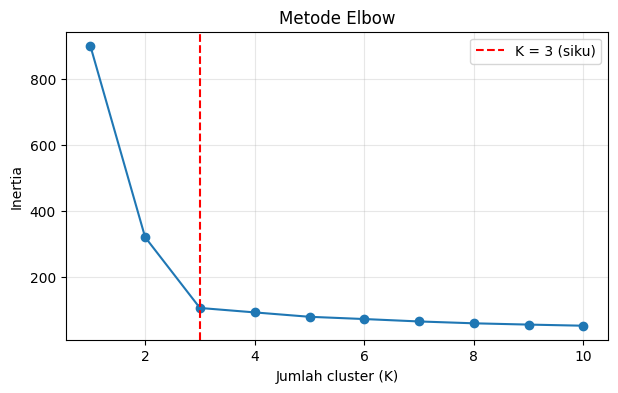

In [4]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1, 11), inertias, marker='o')
plt.axvline(3, color='red', linestyle='--', label='K = 3 (siku)')
plt.xlabel('Jumlah cluster (K)'); plt.ylabel('Inertia')
plt.title('Metode Elbow'); plt.legend(); plt.grid(alpha=.3); plt.show()

## Langkah 3 — Menjalankan K-Means (K=3)

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0    100
1    100
2    100
Name: count, dtype: int64


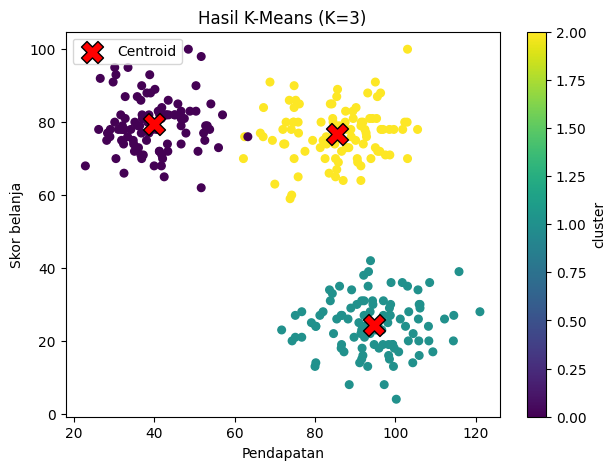

In [6]:
# Visualisasi hasil: pendapatan vs skor belanja
plt.figure(figsize=(7,5))
sc = plt.scatter(df['pendapatan'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=30)
cent = StandardScaler().fit(df[['usia','pendapatan','skor_belanja']]).inverse_transform(kmeans.cluster_centers_)
plt.scatter(cent[:,1], cent[:,2], c='red', marker='X', s=250, edgecolor='k', label='Centroid')
plt.xlabel('Pendapatan'); plt.ylabel('Skor belanja'); plt.title('Hasil K-Means (K=3)')
plt.legend(); plt.colorbar(sc, label='cluster'); plt.show()

## Langkah 4 — Evaluasi silhouette score

In [7]:
sil3 = silhouette_score(X_scaled, df['cluster'])
print('Silhouette (K=3):', round(sil3, 4))

Silhouette (K=3): 0.646


## Langkah 5 — Interpretasi: profil rata-rata tiap cluster

In [8]:
profil = df.groupby('cluster')[['usia','pendapatan','skor_belanja']].mean().round(1)
print(profil)

         usia  pendapatan  skor_belanja
cluster                                
0        24.8        39.9          79.5
1        45.4        94.6          24.3
2        34.5        85.4          76.8


In [9]:
# Penamaan cluster otomatis berdasarkan profil (nomor cluster bisa berbeda tiap run, jadi pakai aturan)
nama = {}
nama[profil['usia'].idxmax()] = 'Mapan Hemat'                       # paling tua, belanja rendah
sisa = profil.drop(index=profil['usia'].idxmax())
nama[sisa['pendapatan'].idxmax()] = 'Sultan Royal'                  # pendapatan tertinggi, belanja tinggi
nama[sisa['pendapatan'].idxmin()] = 'Muda Trendi'                   # termuda, pendapatan menengah, belanja tinggi

df['segmen'] = df['cluster'].map(nama)
profil['nama_segmen'] = profil.index.map(nama)
profil['jumlah'] = df['cluster'].value_counts().sort_index()
profil

,usia,pendapatan,skor_belanja,nama_segmen,jumlah
cluster,,,,,
0,24.8,39.9,79.5,Muda Trendi,100
1,45.4,94.6,24.3,Mapan Hemat,100
2,34.5,85.4,76.8,Sultan Royal,100


**Penamaan cluster (periksa & sesuaikan dengan profil di atas):**
- **Muda Trendi** — usia muda, pendapatan menengah, skor belanja tinggi → target promo & tren.
- **Sultan Royal** — usia dewasa, pendapatan tinggi, skor belanja tinggi → program loyalitas/premium.
- **Mapan Hemat** — usia lebih tua, pendapatan tinggi, skor belanja rendah → potensi besar, perlu di-engage.

## Latihan Mandiri

### Latihan 6 — K=5 vs K=3

Silhouette K=3: 0.6460
Silhouette K=5: 0.4110


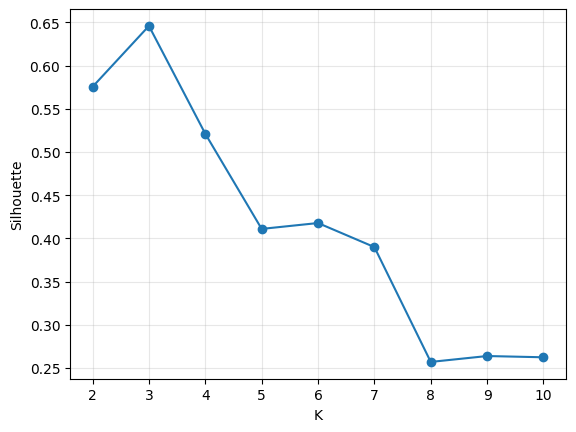

In [10]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
lab5 = km5.fit_predict(X_scaled)
sil5 = silhouette_score(X_scaled, lab5)
print(f'Silhouette K=3: {sil3:.4f}')
print(f'Silhouette K=5: {sil5:.4f}')

# Bonus: silhouette untuk semua K
ks = range(2, 11)
sils = [silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)) for k in ks]
plt.plot(ks, sils, marker='o'); plt.xlabel('K'); plt.ylabel('Silhouette'); plt.grid(alpha=.3); plt.show()

**Kesimpulan 6:** (isi sendiri) Silhouette K=3 lebih tinggi dari K=5, artinya K=3 menghasilkan cluster yang lebih kompak dan terpisah; K=5 memecah kelompok alami menjadi bagian-bagian yang saling berdekatan.

### Latihan 7 — K-Means tanpa scaling (K=3)

In [11]:
X_raw = df[['usia','pendapatan','skor_belanja']].values
lab_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_raw)

print('Silhouette dengan scaling   :', round(silhouette_score(X_scaled, df['cluster']), 4))
print('Silhouette tanpa scaling    :', round(silhouette_score(X_raw, lab_raw), 4))
print('\nRentang fitur (std):'); print(df[['usia','pendapatan','skor_belanja']].std().round(1))

Silhouette dengan scaling   : 0.646
Silhouette tanpa scaling    : 0.6774

Rentang fitur (std):
usia             9.1
pendapatan      25.7
skor_belanja    26.4
dtype: float64


**Kesimpulan 7:** (pada data ini silhouette tanpa scaling ≈ 0.68, sedikit lebih tinggi dari dengan scaling ≈ 0.65). Angka ini TIDAK bisa dibandingkan langsung karena dihitung pada ruang fitur yang berbeda: tanpa scaling, jarak didominasi pendapatan dan skor belanja (std ≈ 26) sedangkan usia (std ≈ 9) berkontribusi kecil, sehingga silhouette yang tinggi hanya mencerminkan keterpisahan pada fitur dominan. Scaling tetap wajib agar semua fitur berkontribusi setara; pada data lain dengan perbedaan skala ekstrem, melewatkan scaling dapat membuat cluster sangat bias.

### Latihan 8 — Scatter plot usia (x) vs skor_belanja (y)

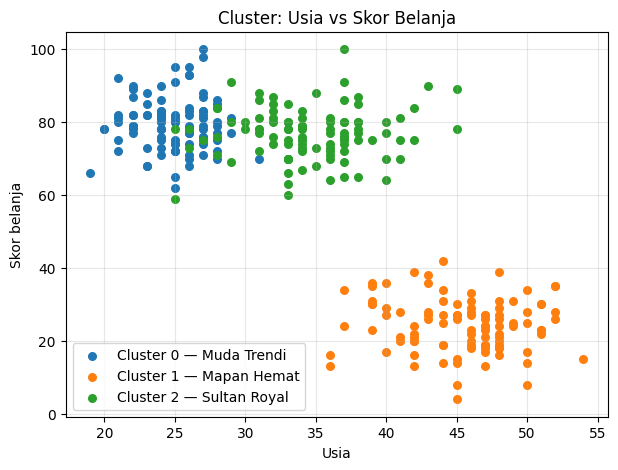

In [12]:
plt.figure(figsize=(7,5))
for c in sorted(df['cluster'].unique()):
    d = df[df['cluster'] == c]
    plt.scatter(d['usia'], d['skor_belanja'], label=f'Cluster {c} — {nama[c]}', s=30)
plt.xlabel('Usia'); plt.ylabel('Skor belanja'); plt.title('Cluster: Usia vs Skor Belanja')
plt.legend(); plt.grid(alpha=.3); plt.show()

## Refleksi

**9. Bagaimana K-Means menemukan kelompok tanpa label?**

K-Means memilih K centroid awal secara acak, lalu mengulang dua langkah: (1) *assignment* — tiap titik dimasukkan ke centroid terdekat berdasarkan jarak Euclidean; (2) *update* — centroid dihitung ulang sebagai rata-rata anggotanya. Proses berhenti saat konvergen (centroid tidak berubah/inertia stabil). Kelompok terbentuk dari kemiripan jarak antar data, tanpa memerlukan label.

**10. Mengapa Elbow menunjukkan siku di K=3 pada data ini?**

Data dibangkitkan dari 3 kelompok alami. Dari K=1 ke K=3 inertia turun tajam karena tiap penambahan cluster memisahkan kelompok sebenarnya. Setelah K=3, cluster tambahan hanya memecah kelompok yang sudah kompak sehingga penurunan inertia kecil (landai) — membentuk siku.

**11. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**

K-Means berbasis jarak. Fitur dengan skala/rentang besar (mis. pendapatan) mendominasi jarak, sehingga fitur berskala kecil (usia, skor) diabaikan. Akibatnya cluster bias, tidak mencerminkan semua fitur, dan hasilnya menyesatkan. StandardScaler menyamakan kontribusi tiap fitur.

## Kesimpulan
Metode Elbow menunjukkan siku pada K=3, sehingga jumlah cluster optimal adalah 3. K-Means dengan K=3 menghasilkan silhouette score 0,646, lebih baik daripada K=5 yang hanya 0,411, artinya cluster pada K=3 lebih kompak dan terpisah jelas. Tiga segmen pelanggan yang terbentuk adalah Muda Trendi (usia ±25, pendapatan menengah, skor belanja tinggi), Sultan Royal (usia ±35, pendapatan tinggi, skor belanja tinggi), dan Mapan Hemat (usia ±45, pendapatan tinggi, skor belanja rendah). Scaling terbukti wajib karena K-Means berbasis jarak, sehingga fitur berskala besar bisa mendominasi bila tidak distandarisasi. Secara bisnis, Muda Trendi cocok untuk promo tren, Sultan Royal untuk program loyalitas premium, dan Mapan Hemat untuk strategi engagement agar belanjanya meningkat.